# Explaining employee attrition models, and testing whether the explanations hold

**7005SCN Individual Research Project** — Naveen R Nalla (16832440) · Supervisor: Stella Orim

Notebook version of `attrition_xai.py` (same code, same seed, same results). Run top to bottom from the project folder.

- **RQ1** Which characteristics predict attrition, and how consistent is the ranking across models and explanation methods?
- **RQ2** What is the predictive cost of an intrinsically interpretable model vs a black box?
- **RQ3** How far can XAI outputs become actionable, defensible HR guidance?

## 0. Setup: imports and configuration

In [1]:
import os, subprocess, sys, base64, zlib

# Auto-install packages when running in a fresh environment (e.g. Google Colab)
for _pkg, _mod in [("interpret", "interpret"), ("lime", "lime"), ("shap", "shap"), ("xgboost", "xgboost"), ("imbalanced-learn", "imblearn")]:
    try:
        __import__(_mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import os

# Use one thread everywhere. With several threads the order of floating-point sums can
# change between runs, which made RandomForest/XGBoost/EBM results drift slightly.
# These must be set before numpy and the model libraries are imported.
for var in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[var] = "1"

import hashlib
import json
import time
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from imblearn.over_sampling import SMOTE, RandomOverSampler
from interpret.glassbox import ExplainableBoostingClassifier
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import rankdata, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
ROOT = Path.cwd()  # run from the project folder
DATA = ROOT / "data" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
SHA256 = "a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659"
RES, FIG = ROOT / "results", ROOT / "figures"
N_BOOT = 30          # bootstrap refits per model
N_LIME = 50          # employees explained with LIME (25 leavers + 25 stayers from the test set)
LIME_SEEDS = 5       # LIME re-runs with only the seed changed
N_PERTURB = 10       # noise draws for the input-perturbation test
NOISE_SD = 0.1       # perturbation size, in training standard deviations
TOPK = 5

GLASS = ["LogReg", "DecisionTree", "EBM"]
BLACK = ["RandomForest", "XGBoost"]
MODELS = GLASS + BLACK
STRATS = ["none", "class_weight", "oversample", "smote"]
GRIDS = {
    "LogReg": {"C": [0.01, 0.1, 1.0]},
    "DecisionTree": {"max_depth": [3, 4, 5], "min_samples_leaf": [10, 25]},
    "EBM": {"max_leaves": [2, 3]},
    "RandomForest": {"max_depth": [None, 8], "min_samples_leaf": [1, 5]},
    "XGBoost": {"max_depth": [2, 3, 4]},
}
PROTECTED = ["Age", "Gender", "MaritalStatus"]
# Can the organisation legitimately change this? Used for RQ3 guidance, not by any model.
ACTIONABILITY = {
    "OverTime": "Actionable", "MonthlyIncome": "Actionable", "StockOptionLevel": "Actionable",
    "JobSatisfaction": "Actionable", "EnvironmentSatisfaction": "Actionable",
    "WorkLifeBalance": "Actionable", "JobInvolvement": "Actionable",
    "RelationshipSatisfaction": "Actionable", "BusinessTravel": "Actionable",
    "YearsSinceLastPromotion": "Actionable", "JobLevel": "Actionable",
    "TrainingTimesLastYear": "Actionable", "PercentSalaryHike": "Actionable",
    "YearsWithCurrManager": "Partly actionable", "YearsInCurrentRole": "Partly actionable",
    "JobRole": "Partly actionable", "Department": "Partly actionable",
    "DistanceFromHome": "Partly actionable",
    "TotalWorkingYears": "Not actionable (history)", "YearsAtCompany": "Not actionable (history)",
    "NumCompaniesWorked": "Not actionable (history)", "Education": "Not actionable (history)",
    "EducationField": "Not actionable (history)", "PerformanceRating": "Not actionable (history)",
    "Age": "Protected / personal", "Gender": "Protected / personal",
    "MaritalStatus": "Protected / personal",
    "DailyRate": "Unclear meaning", "HourlyRate": "Unclear meaning", "MonthlyRate": "Unclear meaning",
}
from IPython.display import Image, Markdown, display
pd.set_option('display.precision', 3)
pd.set_option('display.width', 200)
# Ensure folders and dataset exist even when opened standalone in Google Colab
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    _alt = ROOT / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
    if _alt.exists():
        DATA.write_bytes(_alt.read_bytes())
    else:
        DATA.write_bytes(zlib.decompress(base64.b64decode("...")))


/workspace/naveen/venv_nb/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data: load, checksum, encode
Constant and identifier columns dropped; categoricals one-hot encoded into one shared 51-column matrix. Attributions are later summed back to the 30 original characteristics.

In [2]:
def load():
    assert hashlib.sha256(DATA.read_bytes()).hexdigest() == SHA256, "dataset checksum mismatch"
    df = pd.read_csv(DATA, encoding="utf-8-sig")
    y = (df.pop("Attrition") == "Yes").astype(int).to_numpy()
    df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])
    cats = df.select_dtypes("object").columns.tolist()
    X = pd.get_dummies(df, columns=cats, prefix_sep="=", dtype=float)
    assert X.shape[1] == 51, X.shape
    return df, X, y


DF, XDF, Y = load()
COLS = XDF.columns.tolist()
NF = len(COLS)
NUM = [i for i, c in enumerate(COLS) if "=" not in c]
DUMMY = [i for i, c in enumerate(COLS) if "=" in c]
CONT = [i for i in NUM if XDF.iloc[:, i].nunique() > 10]

# The 30 original employee characteristics. A one-hot column such as "JobRole=Manager"
# belongs to the characteristic "JobRole".
FEATS = []
for c in COLS:
    base = c.split("=")[0]
    if base not in FEATS:
        FEATS.append(base)

# For each characteristic, the list of encoded column positions that belong to it.
GROUP_COLUMNS = {}
for f in FEATS:
    GROUP_COLUMNS[f] = [i for i, c in enumerate(COLS) if c.split("=")[0] == f]


def group(A):
    """Sum one-hot attributions back to the original characteristic (51 -> 30 columns).

    Example: the SHAP values of all the JobRole=... columns are added together to give a
    single value for JobRole. Works for one row (1-D) or many rows (2-D)."""
    A = np.asarray(A, dtype=float)
    one_row = A.ndim == 1
    if one_row:
        A = A.reshape(1, -1)
    out = np.zeros((A.shape[0], len(FEATS)))
    for j, f in enumerate(FEATS):
        out[:, j] = A[:, GROUP_COLUMNS[f]].sum(axis=1)
    if one_row:
        return out[0]
    return out

In [3]:
print(f"rows={len(Y)}, encoded columns={NF}, characteristics={len(FEATS)}, attrition rate={Y.mean():.3f}")
print(f"majority-class accuracy = {1 - Y.mean():.3f}  (why accuracy is not used)")
XDF.head()

rows=1470, encoded columns=51, characteristics=30, attrition rate=0.161
majority-class accuracy = 0.839  (why accuracy is not used)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole=Manufacturing Director,JobRole=Research Director,JobRole=Research Scientist,JobRole=Sales Executive,JobRole=Sales Representative,MaritalStatus=Divorced,MaritalStatus=Married,MaritalStatus=Single,OverTime=No,OverTime=Yes
0,41,1102,1,2,2,94,3,2,4,5993,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1,49,279,8,1,3,61,2,2,2,5130,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,37,1373,2,2,4,92,2,1,3,2090,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,33,1392,3,4,4,56,3,1,3,2909,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,27,591,2,1,1,40,3,1,2,3468,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 2. Models and explainers
Scaling and resampling are fitted on training rows only. SHAP: exact linear SHAP for LogReg, centred term contributions for the additive EBM, TreeSHAP for the trees. LIME on the same scaled inputs.

In [4]:
def make(name, seed, **p):
    if name == "LogReg":
        return LogisticRegression(max_iter=5000, **p)
    if name == "DecisionTree":
        return DecisionTreeClassifier(random_state=seed, **p)
    if name == "EBM":
        # interactions=0 keeps the EBM purely additive, so each term is exactly one feature
        return ExplainableBoostingClassifier(interactions=0, feature_names=COLS, random_state=seed,
                                             n_jobs=1, **p)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=seed, **p)
    return XGBClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", n_jobs=1, random_state=seed, **p)


class Fitted:
    """Scaler + model fitted together; scaling and resampling only ever see training rows."""

    def __init__(self, name, sc, m, mu, center):
        self.name = name        # model name, e.g. "EBM"
        self.sc = sc            # StandardScaler fitted on the training rows
        self.m = m              # the fitted model
        self.mu = mu            # mean of the scaled training data (used by linear SHAP)
        self.center = center    # EBM only: average term contribution on the training rows

    def tx(self, X):
        Z = X.copy()
        Z[:, NUM] = self.sc.transform(X[:, NUM])
        return Z

    def proba(self, X):
        return self.m.predict_proba(self.tx(X))[:, 1]


def fit(name, params, strat, X, y, seed=SEED):
    sc = StandardScaler().fit(X[:, NUM])
    Z = X.copy()
    Z[:, NUM] = sc.transform(X[:, NUM])
    mu = Z.mean(0)
    w = None
    if strat == "class_weight":
        w = compute_sample_weight("balanced", y)
    elif strat == "oversample":
        Z, y = RandomOverSampler(random_state=seed).fit_resample(Z, y)
    elif strat == "smote":
        Z, y = SMOTE(random_state=seed).fit_resample(Z, y)
    m = make(name, seed, **params)
    m.fit(Z, y, sample_weight=w)
    f = Fitted(name, sc, m, mu, None)
    if name == "EBM":
        f.center = m.eval_terms(f.tx(X)).mean(0)   # centre on the real (un-resampled) training rows
    return f


def shap_local(f, Zs):
    """Local attributions on scaled inputs, 51 columns.
    LogReg: exact linear SHAP (coef * (x - mean)), log-odds.
    EBM: its own additive term contributions, centred on training data (= SHAP for an additive model), log-odds.
    Trees: TreeSHAP (DecisionTree/RandomForest in probability units, XGBoost in log-odds)."""
    if f.name == "LogReg":
        return (Zs - f.mu) * f.m.coef_[0]
    if f.name == "EBM":
        return f.m.eval_terms(Zs) - f.center
    sv = shap.TreeExplainer(f.m).shap_values(Zs, check_additivity=False)
    if isinstance(sv, list):
        sv = sv[1]
    return sv[:, :, 1] if sv.ndim == 3 else sv


def intrinsic_global(f, Ztr):
    """What the glass-box model reports about itself, grouped to 30 characteristics."""
    if f.name == "LogReg":
        return group(np.abs(f.m.coef_[0]) * Ztr.std(0))       # standardised |coefficient|
    if f.name == "EBM":
        return group(np.asarray(f.m.term_importances()))       # mean |term contribution|
    if f.name == "DecisionTree":
        return group(f.m.feature_importances_)                 # impurity importance
    return None


def lime_local(f, Ztr, Zrows, seed):
    ex = LimeTabularExplainer(Ztr, feature_names=COLS, class_names=["stay", "leave"],
                              categorical_features=DUMMY, discretize_continuous=True,
                              random_state=seed, mode="classification")
    out = np.zeros((len(Zrows), NF))
    for i, z in enumerate(Zrows):
        e = ex.explain_instance(z, f.m.predict_proba, labels=(1,), num_features=NF)
        for j, w in e.as_map()[1]:
            out[i, j] = w
    return out

## 3. Metric and audit helpers

In [5]:
def row_spearman(A, B):
    """Spearman correlation between row i of A and row i of B, for every row (employee).

    Spearman = Pearson correlation of the ranks. If a row is constant the correlation
    is undefined, so NaN is returned for that row (later averaged with np.nanmean)."""
    result = []
    for a, b in zip(A, B):
        ra = rankdata(a)
        rb = rankdata(b)
        ra = ra - ra.mean()
        rb = rb - rb.mean()
        denominator = np.sqrt((ra ** 2).sum() * (rb ** 2).sum())
        if denominator == 0:
            result.append(np.nan)
        else:
            result.append((ra * rb).sum() / denominator)
    return np.array(result)


def topk_jaccard(A, B, k=TOPK):
    """For each row, the overlap (Jaccard index) of the k features with the largest |attribution|.

    1 means both explanations name the same top-k features, 0 means none in common."""
    top_a = np.argsort(-np.abs(A), 1)[:, :k]
    top_b = np.argsort(-np.abs(B), 1)[:, :k]
    result = []
    for a, b in zip(top_a, top_b):
        common = set(a) & set(b)
        either = set(a) | set(b)
        result.append(len(common) / len(either))
    return np.array(result)


def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[np.argmax(f1[:-1])])


def scores(y, p, t):
    """Test-set metrics. ROC-AUC and PR-AUC use the probabilities; the others use threshold t."""
    yh = (p >= t).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y, p),
        "PR_AUC": average_precision_score(y, p),
        "Recall": recall_score(y, yh),
        "Precision": precision_score(y, yh, zero_division=0),
        "F1": f1_score(y, yh),
        "Threshold": t,
    }


def paired_boot(y, pa, pb, metric, n=2000):
    """Difference metric(model A) - metric(model B) on the test set, with a 95% bootstrap CI.

    "Paired" means both models are scored on the same resampled employees each time,
    so the CI reflects the difference between the models and not the test-set luck."""
    rng = np.random.default_rng(SEED)
    differences = []
    while len(differences) < n:
        i = rng.integers(0, len(y), len(y))
        # skip resamples that contain only one class, because the AUC is undefined there
        if y[i].min() != y[i].max():
            differences.append(metric(y[i], pa[i]) - metric(y[i], pb[i]))
    observed = metric(y, pa) - metric(y, pb)
    ci_low, ci_high = np.percentile(differences, [2.5, 97.5])
    return observed, ci_low, ci_high


def cv_oof(name, params, strat, X, y):
    """5-fold CV on the training data. Returns the out-of-fold probabilities and, per fold,
    (ROC-AUC, PR-AUC). The model is refitted inside each fold, so nothing leaks."""
    oof = np.zeros(len(y))
    folds = []
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
        p = fit(name, params, strat, X[tr], y[tr]).proba(X[va])
        oof[va] = p
        folds.append((roc_auc_score(y[va], p), average_precision_score(y[va], p)))
    return oof, np.array(folds)


def age_band(a):
    return np.where(a < 30, "<30", np.where(a < 45, "30-44", "45+"))


def subgroup_table(y, p, t, groups, label):
    rows = []
    for g in sorted(set(groups)):
        m = groups == g
        yh = (p[m] >= t).astype(int)
        yt = y[m]
        rows.append({"Attribute": label, "Group": g, "n": int(m.sum()), "BaseRate": yt.mean(),
                     "SelectionRate": yh.mean(),
                     "TPR": yh[yt == 1].mean() if (yt == 1).any() else np.nan,
                     "FPR": yh[yt == 0].mean() if (yt == 0).any() else np.nan,
                     "Precision": yt[yh == 1].mean() if yh.any() else np.nan,
                     "PR_AUC": average_precision_score(yt, p[m]) if 0 < yt.sum() < len(yt) else np.nan})
    return rows

## Run setup: output folders and train/test split

In [6]:
t0 = time.time()
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

def log(message):
    """Print progress with the number of seconds since the start."""
    print(f"[{time.time() - t0:6.0f}s] {message}", flush=True)

X = XDF.to_numpy()
idx = np.arange(len(Y))
tr, te = train_test_split(idx, test_size=0.2, stratify=Y, random_state=SEED)
Xtr, Xte, ytr, yte = X[tr], X[te], Y[tr], Y[te]
summary = {
    "n_rows": len(Y),
    "n_features_encoded": NF,
    "n_characteristics": len(FEATS),
    "attrition_rate": float(Y.mean()),
    "majority_accuracy": float(1 - Y.mean()),   # accuracy of always predicting "stays"
    "n_train": len(tr),
    "n_test": len(te),
    "test_positives": int(yte.sum()),
}
log(f"data ok: {X.shape}, attrition {Y.mean():.3f}")

[     0s] data ok: (1470, 51), attrition 0.161


## 4. Class-imbalance strategies inside 5-fold CV (RQ2)

In [7]:
# ---- 1. imbalance strategy x hyper-parameters, 5-fold CV on training data (RQ2)
# Every model is tried with every imbalance strategy and every grid setting.
# The best configuration for each model is the one with the highest mean CV PR-AUC,
# because PR-AUC is more informative than accuracy when only 16% of employees leave.
rows = []
oofs = {}   # out-of-fold predictions, kept so that the threshold can be chosen later
for name in MODELS:
    for strat in STRATS:
        for params in ParameterGrid(GRIDS[name]):
            oof, fo = cv_oof(name, params, strat, Xtr, ytr)
            rows.append({"Model": name, "Strategy": strat, "Params": json.dumps(params),
                         "CV_ROC_AUC": fo[:, 0].mean(), "CV_ROC_AUC_sd": fo[:, 0].std(),
                         "CV_PR_AUC": fo[:, 1].mean(), "CV_PR_AUC_sd": fo[:, 1].std()})
            oofs[(name, strat, json.dumps(params))] = (oof, fo)
    log(f"CV done: {name}")
cv = pd.DataFrame(rows)
cv.to_csv(RES / "cv_all_configs.csv", index=False)
# best grid setting for each (model, strategy) pair -> Table of imbalance strategies
best_rows = cv.groupby(["Model", "Strategy"]).CV_PR_AUC.idxmax()
imb = cv.loc[best_rows]
imb.to_csv(RES / "imbalance_comparison.csv", index=False)
# best overall configuration for each model
best_rows = cv.groupby("Model").CV_PR_AUC.idxmax()
best = cv.loc[best_rows].set_index("Model").loc[MODELS]

[     1s] CV done: LogReg


[     2s] CV done: DecisionTree


[   556s] CV done: EBM


[   600s] CV done: RandomForest


[   607s] CV done: XGBoost


In [8]:
display(imb.pivot(index='Model', columns='Strategy', values='CV_PR_AUC'))

Strategy,class_weight,none,oversample,smote
Model,,,,
DecisionTree,0.379,0.391,0.386,0.333
EBM,0.675,0.687,0.549,0.665
LogReg,0.630,0.651,0.613,0.615
RandomForest,0.568,0.574,0.567,0.594
XGBoost,0.618,0.639,0.602,0.643


## 5. Final models, held-out test performance and the cost of interpretability (RQ2)

In [9]:
# ---- 2. final fit + held-out test evaluation
# Each model is refitted on the whole training set with its best configuration.
# The decision threshold is chosen on the out-of-fold predictions (not on the test set).
final = {}     # fitted models
ptest = {}     # predicted probabilities on the test set
perf = []      # rows of the performance table
fold_pr = {}   # PR-AUC of each CV fold, for the fold-paired comparison
for name in MODELS:
    b = best.loc[name]
    params = json.loads(b.Params)
    strat = b.Strategy
    oof, fo = oofs[(name, strat, b.Params)]
    fold_pr[name] = fo[:, 1]
    t = best_f1_threshold(ytr, oof)
    f = fit(name, params, strat, Xtr, ytr)
    final[name] = f
    ptest[name] = f.proba(Xte)

    row = {"Model": name,
           "Type": "Glass-box" if name in GLASS else "Black-box",
           "Strategy": strat,
           "Params": b.Params,
           "CV_ROC_AUC": b.CV_ROC_AUC,
           "CV_PR_AUC": b.CV_PR_AUC,
           "CV_PR_AUC_sd": b.CV_PR_AUC_sd}
    test_scores = scores(yte, ptest[name], t)
    for metric_name, value in test_scores.items():
        row["Test_" + metric_name] = value
    row["OOF"] = oof   # kept for the subgroup audit, not written to the CSV
    perf.append(row)
perf_df = pd.DataFrame(perf)
perf_df.drop(columns="OOF").to_csv(RES / "performance.csv", index=False)
log("final models fitted")

# cost of interpretability (RQ2): each glass-box model vs the best black-box model.
# A negative difference means the glass-box model is worse.
if best.loc["RandomForest"].CV_PR_AUC >= best.loc["XGBoost"].CV_PR_AUC:
    bb = "RandomForest"
else:
    bb = "XGBoost"
cost = []
for g in GLASS:
    # (i) on the test set, with a paired-bootstrap 95% CI
    for mname, fn in [("PR_AUC", average_precision_score), ("ROC_AUC", roc_auc_score)]:
        d, lo, hi = paired_boot(yte, ptest[g], ptest[bb], fn)
        cost.append({"GlassBox": g, "vs": bb, "Metric": mname, "Diff": d, "CI_low": lo, "CI_high": hi})
    # (ii) on the 5 CV folds: mean difference, and the smallest and largest fold difference
    fold_diff = fold_pr[g] - fold_pr[bb]
    cost.append({"GlassBox": g, "vs": bb, "Metric": "CV_PR_AUC (fold-paired)",
                 "Diff": fold_diff.mean(), "CI_low": fold_diff.min(), "CI_high": fold_diff.max()})
pd.DataFrame(cost).to_csv(RES / "interpretability_cost.csv", index=False)

[   612s] final models fitted


In [10]:
display(perf_df.drop(columns=['OOF', 'Params']))
display(pd.DataFrame(cost))

,Model,Type,Strategy,CV_ROC_AUC,CV_PR_AUC,CV_PR_AUC_sd,Test_ROC_AUC,Test_PR_AUC,Test_Recall,Test_Precision,Test_F1,Test_Threshold
0,LogReg,Glass-box,none,0.839,0.651,0.061,0.812,0.584,0.447,0.553,0.494,0.368
1,DecisionTree,Glass-box,none,0.722,0.391,0.046,0.684,0.310,0.447,0.389,0.416,0.167
2,EBM,Glass-box,none,0.850,0.687,0.050,0.828,0.578,0.447,0.553,0.494,0.338
3,RandomForest,Black-box,smote,0.819,0.594,0.049,0.794,0.497,0.511,0.462,0.485,0.392
4,XGBoost,Black-box,smote,0.830,0.643,0.060,0.811,0.565,0.468,0.500,0.484,0.376


,GlassBox,vs,Metric,Diff,CI_low,CI_high
0,LogReg,XGBoost,PR_AUC,1.891e-02,-0.058,0.096
1,LogReg,XGBoost,ROC_AUC,8.614e-05,-0.039,0.039
2,LogReg,XGBoost,CV_PR_AUC (fold-paired),8.468e-03,-0.010,0.021
3,DecisionTree,XGBoost,PR_AUC,-2.547e-01,-0.362,-0.131
4,DecisionTree,XGBoost,ROC_AUC,-1.275e-01,-0.205,-0.057
5,DecisionTree,XGBoost,CV_PR_AUC (fold-paired),-2.517e-01,-0.292,-0.219
6,EBM,XGBoost,PR_AUC,1.297e-02,-0.038,0.067
7,EBM,XGBoost,ROC_AUC,1.680e-02,-0.007,0.041
8,EBM,XGBoost,CV_PR_AUC (fold-paired),4.409e-02,-0.003,0.076


## 6. Explanations: SHAP, LIME, intrinsic — global rankings and agreement (RQ1)

In [11]:
# ---- 3. explanations: SHAP for every test employee, LIME for a 50-employee panel (RQ1)
# LIME is slow, so it is run on a fixed panel of 25 leavers and 25 stayers from the test set.
rng = np.random.default_rng(SEED)
leavers = np.where(yte == 1)[0]
stayers = np.where(yte == 0)[0]
panel_leavers = rng.choice(leavers, N_LIME // 2, replace=False)
panel_stayers = rng.choice(stayers, N_LIME // 2, replace=False)
panel = np.concatenate([panel_leavers, panel_stayers])
summary["lime_panel_size"] = len(panel)
glob = {}    # global importance: one column per model|method
phis = {}    # SHAP values per model (test employees x 30 characteristics)
limes = {}   # LIME values per model, one array per LIME seed
for name in MODELS:
    f = final[name]
    Ztr = f.tx(Xtr)
    Zte = f.tx(Xte)
    phis[name] = group(shap_local(f, Zte))
    # LIME is run LIME_SEEDS times with only the random seed changed (used in stability test (c))
    limes[name] = []
    for s in range(LIME_SEEDS):
        limes[name].append(group(lime_local(f, Ztr, Zte[panel], SEED + s)))
    # global importance = mean absolute attribution over employees
    glob[f"{name}|SHAP"] = np.abs(phis[name]).mean(0)
    glob[f"{name}|LIME"] = np.abs(limes[name][0]).mean(0)
    ig = intrinsic_global(f, Ztr)
    if ig is not None:
        glob[f"{name}|Intrinsic"] = ig
    log(f"explained: {name}")
gdf = pd.DataFrame(glob, index=FEATS)
gdf.to_csv(RES / "global_importance.csv")
ranks = gdf.rank(ascending=False)
ranks.to_csv(RES / "global_ranks.csv")
rho = gdf.corr(method="spearman")
rho.to_csv(RES / "rank_agreement_spearman.csv")
shap_cols = [f"{m}|SHAP" for m in MODELS]
# overlap of the top-10 lists for every pair of model|method columns
top10 = {}
for c in gdf.columns:
    top10[c] = set(ranks[c].nsmallest(10).index)
jac10 = pd.DataFrame(index=gdf.columns, columns=gdf.columns, dtype=float)
for a in gdf.columns:
    for b in gdf.columns:
        jac10.loc[a, b] = len(top10[a] & top10[b]) / len(top10[a] | top10[b])
jac10.to_csv(RES / "rank_agreement_top10_jaccard.csv")

# SHAP vs LIME, employee by employee, same model
sl = []
for name in MODELS:
    S = phis[name][panel]   # SHAP for the panel employees
    L = limes[name][0]      # LIME (first seed) for the same employees
    # sign agreement: for each employee, take SHAP's top-5 features and check whether
    # LIME pushes each of them in the same direction (towards leaving or staying)
    top_s = np.argsort(-np.abs(S), 1)[:, :TOPK]
    sign_per_employee = []
    for i in range(len(S)):
        same_sign = np.sign(S[i, top_s[i]]) == np.sign(L[i, top_s[i]])
        sign_per_employee.append(same_sign.mean())
    sign = np.array(sign_per_employee)
    sl.append({"Model": name, "Spearman_mean": np.nanmean(row_spearman(S, L)),
               "Top5_Jaccard_mean": topk_jaccard(S, L).mean(),
               "Top1_same": (np.abs(S).argmax(1) == np.abs(L).argmax(1)).mean(),
               "Top5_sign_agreement": sign.mean()})
pd.DataFrame(sl).to_csv(RES / "shap_vs_lime.csv", index=False)

[   647s] explained: LogReg


[   659s] explained: DecisionTree


[   670s] explained: EBM


[   703s] explained: RandomForest


[   716s] explained: XGBoost


In [12]:
display(ranks.sort_values('XGBoost|SHAP').head(12))
display(rho.round(2))
display(pd.DataFrame(sl))

,LogReg|SHAP,LogReg|LIME,LogReg|Intrinsic,DecisionTree|SHAP,DecisionTree|LIME,DecisionTree|Intrinsic,EBM|SHAP,EBM|LIME,EBM|Intrinsic,RandomForest|SHAP,RandomForest|LIME,XGBoost|SHAP,XGBoost|LIME
OverTime,1.0,1.0,2.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0
StockOptionLevel,16.0,22.0,17.0,20.5,21.0,20.5,8.0,30.0,10.0,4.0,2.0,2.0,2.0
EnvironmentSatisfaction,3.0,5.0,8.0,20.5,23.0,20.5,3.0,7.0,5.0,15.0,9.0,3.0,3.0
BusinessTravel,14.0,3.0,3.0,20.5,12.0,20.5,9.0,5.0,4.0,10.0,5.0,4.0,5.0
JobLevel,19.0,25.0,20.0,20.5,22.0,20.5,23.0,24.0,23.0,3.0,25.0,5.0,23.0
JobRole,2.0,2.0,1.0,9.0,7.0,6.0,2.0,2.0,1.0,5.0,3.0,6.0,6.0
NumCompaniesWorked,5.0,4.0,7.0,5.0,6.0,10.0,4.0,6.0,6.0,14.0,18.0,7.0,12.0
JobSatisfaction,7.0,10.0,10.0,20.5,30.0,20.5,10.0,13.0,11.0,12.0,12.0,8.0,10.0
YearsWithCurrManager,8.0,14.0,12.0,20.5,17.0,20.5,12.0,18.0,14.0,6.0,10.0,9.0,11.0
Age,9.0,15.0,11.0,7.0,10.0,7.0,6.0,11.0,7.0,7.0,14.0,10.0,13.0


,LogReg|SHAP,LogReg|LIME,LogReg|Intrinsic,DecisionTree|SHAP,DecisionTree|LIME,DecisionTree|Intrinsic,EBM|SHAP,EBM|LIME,EBM|Intrinsic,RandomForest|SHAP,RandomForest|LIME,XGBoost|SHAP,XGBoost|LIME
LogReg|SHAP,1.00,0.86,0.89,0.29,0.18,0.24,0.81,0.66,0.75,0.62,0.59,0.70,0.69
LogReg|LIME,0.86,1.00,0.92,0.28,0.33,0.23,0.79,0.88,0.83,0.51,0.70,0.70,0.76
LogReg|Intrinsic,0.89,0.92,1.00,0.27,0.30,0.23,0.78,0.80,0.83,0.58,0.66,0.72,0.68
DecisionTree|SHAP,0.29,0.28,0.27,1.00,0.78,0.98,0.39,0.38,0.38,0.29,0.17,0.09,0.05
DecisionTree|LIME,0.18,0.33,0.30,0.78,1.00,0.76,0.32,0.47,0.42,0.35,0.33,0.14,0.10
DecisionTree|Intrinsic,0.24,0.23,0.23,0.98,0.76,1.00,0.35,0.34,0.35,0.26,0.15,0.04,0.01
EBM|SHAP,0.81,0.79,0.78,0.39,0.32,0.35,1.00,0.77,0.96,0.61,0.67,0.82,0.78
EBM|LIME,0.66,0.88,0.80,0.38,0.47,0.34,0.77,1.00,0.85,0.42,0.64,0.62,0.67
EBM|Intrinsic,0.75,0.83,0.83,0.38,0.42,0.35,0.96,0.85,1.00,0.62,0.72,0.81,0.76
RandomForest|SHAP,0.62,0.51,0.58,0.29,0.35,0.26,0.61,0.42,0.62,1.00,0.76,0.73,0.55


,Model,Spearman_mean,Top5_Jaccard_mean,Top1_same,Top5_sign_agreement
0,LogReg,0.932,0.491,0.46,1.000
1,DecisionTree,0.560,0.454,0.76,0.900
2,EBM,0.777,0.489,0.46,0.956
3,RandomForest,0.782,0.456,0.86,0.948
4,XGBoost,0.800,0.432,0.42,0.984


## 7. Stability stress tests: bootstrap refit, 0.1 SD perturbation, LIME seed only (RQ1/RQ3)

In [13]:
# ---- 4. stability stress tests
# (a) model level: refit on bootstrap resamples of the training data
# (b) input level: add small noise to the test inputs, model fixed
# (c) method level: re-run LIME with only the seed changed
stab = []
boot_rank = {}    # rank of each characteristic in each bootstrap refit
boot_top10 = {}   # share of refits in which each characteristic is in the top 10
boot_pred = {}    # predicted risk of each test employee in each refit
for name in MODELS:
    b = best.loc[name]
    params = json.loads(b.Params)
    strat = b.Strategy
    f = final[name]
    Zte = f.tx(Xte)
    g_full = glob[f"{name}|SHAP"]
    # (a) bootstrap refits
    brho = []   # global rank correlation with the full model
    bloc = []   # mean per-employee rank correlation with the full model
    R = []      # ranks
    P = []      # predictions
    brng = np.random.default_rng(SEED + 1)
    for k in range(N_BOOT):
        i = brng.integers(0, len(ytr), len(ytr))
        fb = fit(name, params, strat, Xtr[i], ytr[i], seed=SEED + k)
        ph = group(shap_local(fb, fb.tx(Xte)))
        gb = np.abs(ph).mean(0)
        brho.append(spearmanr(gb, g_full)[0])
        bloc.append(np.nanmean(row_spearman(ph, phis[name])))
        R.append(rankdata(-gb))
        P.append(fb.proba(Xte))
    R = np.array(R)
    P = np.array(P)
    boot_rank[name] = R
    boot_pred[name] = P
    boot_top10[name] = (R <= 10).mean(0)
    # (b) 0.1 SD perturbation of continuous inputs, model fixed
    prho = []    # per-employee Spearman with the unperturbed SHAP values
    pjac = []    # top-5 overlap
    ptop1 = []   # share of employees whose top feature is unchanged
    pdp = []     # mean absolute change in predicted probability
    prng = np.random.default_rng(SEED + 2)
    p0 = f.m.predict_proba(Zte)[:, 1]
    for _ in range(N_PERTURB):
        Zp = Zte.copy()
        Zp[:, CONT] += prng.normal(0, NOISE_SD, (len(Zp), len(CONT)))
        ph = group(shap_local(f, Zp))
        prho.append(np.nanmean(row_spearman(ph, phis[name])))
        pjac.append(topk_jaccard(ph, phis[name]).mean())
        ptop1.append((np.abs(ph).argmax(1) == np.abs(phis[name]).argmax(1)).mean())
        pdp.append(np.abs(f.m.predict_proba(Zp)[:, 1] - p0).mean())
    Zp = Zte[panel].copy()
    Zp[:, CONT] += np.random.default_rng(SEED + 3).normal(0, NOISE_SD, (len(Zp), len(CONT)))
    lp = group(lime_local(f, f.tx(Xtr), Zp, SEED))
    # (c) LIME seed-only reruns
    # compare every pair of LIME seeds (5 seeds -> 10 pairs) and average
    pair_rho, pair_jac, pair_top1 = [], [], []
    for a, c in combinations(range(LIME_SEEDS), 2):
        La = limes[name][a]
        Lc = limes[name][c]
        pair_rho.append(np.nanmean(row_spearman(La, Lc)))
        pair_jac.append(topk_jaccard(La, Lc).mean())
        pair_top1.append((np.abs(La).argmax(1) == np.abs(Lc).argmax(1)).mean())
    ls_rho = np.mean(pair_rho)
    ls_jac = np.mean(pair_jac)
    ls_top1 = np.mean(pair_top1)
    stab.append({"Model": name,
                 "Boot_global_Spearman_mean": np.mean(brho), "Boot_global_Spearman_min": np.min(brho),
                 "Boot_local_Spearman_mean": np.mean(bloc),
                 "Boot_pred_SD_mean": P.std(0).mean(),
                 "Perturb_SHAP_local_Spearman": np.mean(prho), "Perturb_SHAP_top5_Jaccard": np.mean(pjac),
                 "Perturb_SHAP_top1_same": np.mean(ptop1), "Perturb_mean_abs_dProb": np.mean(pdp),
                 "Perturb_LIME_top5_Jaccard": topk_jaccard(lp, limes[name][0]).mean(),
                 "Perturb_LIME_local_Spearman": np.nanmean(row_spearman(lp, limes[name][0])),
                 "LIMEseed_local_Spearman": ls_rho, "LIMEseed_top5_Jaccard": ls_jac,
                 "LIMEseed_top1_same": ls_top1})
    log(f"stability done: {name}")
stab_df = pd.DataFrame(stab)
stab_df.to_csv(RES / "stability.csv", index=False)
pd.DataFrame(boot_top10, index=FEATS).to_csv(RES / "bootstrap_top10_frequency.csv")

[   720s] stability done: LogReg


[   724s] stability done: DecisionTree


[  1157s] stability done: EBM


[  1233s] stability done: RandomForest


[  1243s] stability done: XGBoost


In [14]:
display(stab_df.T)

,0,1,2,3,4
Model,LogReg,DecisionTree,EBM,RandomForest,XGBoost
Boot_global_Spearman_mean,0.741,0.49,0.624,0.864,0.713
Boot_global_Spearman_min,0.548,0.141,0.375,0.737,0.512
Boot_local_Spearman_mean,0.876,0.496,0.789,0.889,0.819
Boot_pred_SD_mean,0.051,0.122,0.084,0.054,0.082
Perturb_SHAP_local_Spearman,0.996,0.96,0.979,0.96,0.968
Perturb_SHAP_top5_Jaccard,0.934,0.932,0.902,0.923,0.912
Perturb_SHAP_top1_same,0.974,0.946,0.921,0.988,0.96
Perturb_mean_abs_dProb,0.008,0.018,0.017,0.024,0.03
Perturb_LIME_top5_Jaccard,0.927,0.953,0.942,0.973,0.973


## 8. Subgroup audit by gender and age band, protected-attribute share and ablation (RQ3)

In [15]:
# ---- 5. subgroup audit (gender, age band) on out-of-fold training predictions and on test (RQ3)
# Done on the out-of-fold training predictions (larger groups) and on the test set.
fair = []
gen = DF["Gender"].to_numpy()
age = age_band(DF["Age"].to_numpy())
for _, r in perf_df.iterrows():
    splits = [("CV-OOF (train)", ytr, r.OOF, tr),
              ("Test", yte, ptest[r.Model], te)]
    for split, yy, pp, ii in splits:
        for label, grp in [("Gender", gen), ("AgeBand", age)]:
            for row in subgroup_table(yy, pp, r.Test_Threshold, grp[ii], label):
                out_row = {"Model": r.Model, "Split": split}
                out_row.update(row)
                fair.append(out_row)
fair_df = pd.DataFrame(fair)
fair_df.to_csv(RES / "subgroup_audit.csv", index=False)
# gap = largest minus smallest value across the groups of one attribute
def spread(values):
    return values.max() - values.min()

gap = fair_df.groupby(["Model", "Split", "Attribute"]).agg(
    TPR_gap=("TPR", spread),
    SelectionRate_gap=("SelectionRate", spread),
    FPR_gap=("FPR", spread),
).reset_index()
gap.to_csv(RES / "subgroup_gaps.csv", index=False)
# share of each model's total SHAP importance that goes to Age, Gender and MaritalStatus
share = pd.DataFrame(index=PROTECTED)
for m in MODELS:
    col = gdf[f"{m}|SHAP"]
    share[m] = col.loc[PROTECTED] / col.sum()
share.loc["Total"] = share.sum()
share.to_csv(RES / "protected_attribute_share.csv")
# ablation: neutralise Age/Gender/MaritalStatus (constant columns carry no information)
prot_idx = [i for i, c in enumerate(COLS) if c.split("=")[0] in PROTECTED]
Xa = Xtr.copy()
Xa[:, prot_idx] = 0.0
abl = []
for name in MODELS:
    b = best.loc[name]
    _, fo = cv_oof(name, json.loads(b.Params), b.Strategy, Xa, ytr)
    abl.append({"Model": name, "CV_PR_AUC_with": b.CV_PR_AUC, "CV_PR_AUC_without_protected": fo[:, 1].mean(),
                "Change": fo[:, 1].mean() - b.CV_PR_AUC})
pd.DataFrame(abl).to_csv(RES / "protected_ablation.csv", index=False)
log("subgroup audit done")

[  1266s] subgroup audit done


In [16]:
display(gap)
display(share)
display(pd.DataFrame(abl))

,Model,Split,Attribute,TPR_gap,SelectionRate_gap,FPR_gap
0,DecisionTree,CV-OOF (train),AgeBand,0.319,2.150e-01,0.111
1,DecisionTree,CV-OOF (train),Gender,0.073,3.371e-03,0.009
2,DecisionTree,Test,AgeBand,0.366,3.405e-01,0.311
3,DecisionTree,Test,Gender,0.109,8.107e-02,0.128
4,EBM,CV-OOF (train),AgeBand,0.515,2.796e-01,0.115
5,EBM,CV-OOF (train),Gender,0.099,1.141e-02,0.020
6,EBM,Test,AgeBand,0.477,1.892e-01,0.117
7,EBM,Test,Gender,0.081,9.686e-05,0.002
8,LogReg,CV-OOF (train),AgeBand,0.410,2.526e-01,0.110
9,LogReg,CV-OOF (train),Gender,0.022,2.846e-02,0.018


,LogReg,DecisionTree,EBM,RandomForest,XGBoost
Age,0.043,0.059,0.054,0.038,0.041
Gender,0.020,0.000,0.017,0.011,0.023
MaritalStatus,0.041,0.105,0.054,0.090,0.034
Total,0.104,0.164,0.125,0.139,0.098


,Model,CV_PR_AUC_with,CV_PR_AUC_without_protected,Change
0,LogReg,0.651,0.632,-1.941e-02
1,DecisionTree,0.391,0.349,-4.236e-02
2,EBM,0.687,0.681,-6.057e-03
3,RandomForest,0.594,0.582,-1.164e-02
4,XGBoost,0.643,0.643,-1.255e-04


## 9. Defensibility tiers (RQ3)

In [17]:
# ---- 6. RQ3: feature defensibility tiers
consensus = ranks[shap_cols].mean(1)
n_top10 = (ranks[shap_cols] <= 10).sum(1)
btop = pd.DataFrame(boot_top10, index=FEATS).mean(1)
sl_agree = (ranks[[f"{m}|LIME" for m in MODELS]] <= 10).sum(1)
tiers = pd.DataFrame({"ConsensusRank_SHAP": consensus, "Models_top10_SHAP": n_top10,
                      "Models_top10_LIME": sl_agree, "Bootstrap_top10_freq": btop,
                      "Actionability": [ACTIONABILITY[f] for f in FEATS]}).sort_values("ConsensusRank_SHAP")

def tier(r):
    robust = r.Models_top10_SHAP >= 4 and r.Bootstrap_top10_freq >= 0.7
    moderate = r.Models_top10_SHAP >= 3 and r.Bootstrap_top10_freq >= 0.4
    if not (robust or moderate):
        return "C: weak or unstable - do not cite as a reason"
    if r.Actionability == "Protected / personal":
        return "P: consistent but protected - never a basis for action; monitor for bias"
    if r.Actionability not in ("Actionable", "Partly actionable"):
        return "H: consistent but historical - context only"
    if robust:
        return "A: robust and actionable - may open a retention conversation"
    return "B: moderately stable and actionable - corroborate with the employee first"

tiers["Tier"] = tiers.apply(tier, axis=1)
tiers.to_csv(RES / "feature_tiers.csv")

In [18]:
display(tiers)

,ConsensusRank_SHAP,Models_top10_SHAP,Models_top10_LIME,Bootstrap_top10_freq,Actionability,Tier
OverTime,1.0,5,5,1.000,Actionable,A: robust and actionable - may open a retentio...
JobRole,4.8,5,5,0.940,Partly actionable,A: robust and actionable - may open a retentio...
MaritalStatus,6.8,3,4,0.447,Protected / personal,P: consistent but protected - never a basis fo...
NumCompaniesWorked,7.0,4,3,0.607,Not actionable (history),H: consistent but historical - context only
Age,7.8,5,1,0.427,Protected / personal,P: consistent but protected - never a basis fo...
EnvironmentSatisfaction,8.9,3,4,0.613,Actionable,B: moderately stable and actionable - corrobor...
StockOptionLevel,10.1,3,2,0.587,Actionable,B: moderately stable and actionable - corrobor...
YearsWithCurrManager,11.1,3,1,0.553,Partly actionable,B: moderately stable and actionable - corrobor...
JobSatisfaction,11.5,3,2,0.480,Actionable,B: moderately stable and actionable - corrobor...
BusinessTravel,11.5,3,4,0.360,Actionable,C: weak or unstable - do not cite as a reason


## 10. Local explanation cards for three test employees (RQ3)

In [19]:
# ---- 7. local explanation cards for three test employees (RQ3)
# the recommended model is the glass-box model with the best CV PR-AUC
rec = GLASS[0]
for m in GLASS:
    if best.loc[m].CV_PR_AUC > best.loc[rec].CV_PR_AUC:
        rec = m
p_rec = ptest[rec]
ph_rec = phis[rec]
t_rec = perf_df.set_index("Model").loc[rec, "Test_Threshold"]
lo, hi = np.percentile(boot_pred[rec], [5, 95], axis=0)
# positions in the panel that are leavers
pos_panel = [k for k, i in enumerate(panel) if yte[i] == 1]
disagree = topk_jaccard(phis[bb][panel], limes[bb][0])
# the leaver with the lowest SHAP/LIME overlap for the best black-box model
worst_k = pos_panel[np.argmin(disagree[pos_panel])]
picks = {
    "Highest-risk employee": int(np.argmax(p_rec)),
    "Borderline employee (closest to threshold)": int(np.argmin(np.abs(p_rec - t_rec))),
    f"Leaver where {bb} SHAP and LIME disagree most": int(panel[worst_k]),
}
lines = [f"# Local explanation cards\n\nModel: **{rec}** (best glass-box by CV PR-AUC); decision threshold "
         f"{t_rec:.3f}. 90% interval = 5th-95th percentile of the predicted risk across {N_BOOT} bootstrap refits.\n"]
for title, i in picks.items():
    order = np.argsort(-np.abs(ph_rec[i]))[:TOPK]
    lines.append(f"## {title}\n\nTest row {i}; actual outcome: {'left' if yte[i] else 'stayed'}; "
                 f"predicted risk {p_rec[i]:.2f} (90% interval {lo[i]:.2f}-{hi[i]:.2f}); "
                 f"{'flagged' if p_rec[i] >= t_rec else 'not flagged'}.\n")
    lines.append("| Characteristic | Value | Contribution (log-odds) | Actionability | Tier |\n|---|---|---|---|---|")
    for j in order:
        fname = FEATS[j]
        val = DF.iloc[te[i]][fname]
        lines.append(f"| {fname} | {val} | {ph_rec[i, j]:+.2f} | {ACTIONABILITY[fname]} | {tiers.loc[fname, 'Tier'][0]} |")
    if i in panel:
        k = int(np.where(panel == i)[0][0])
        lj = topk_jaccard(phis[bb][[i]], limes[bb][0][[k]])[0]
        lines.append(f"\n{bb} top-5 overlap between SHAP and LIME for this employee: {lj:.2f}.")
    lines.append("")
(RES / "local_cases.md").write_text("\n".join(lines))

1887

In [20]:
display(Markdown((RES / 'local_cases.md').read_text()))

# Local explanation cards

Model: **EBM** (best glass-box by CV PR-AUC); decision threshold 0.338. 90% interval = 5th-95th percentile of the predicted risk across 30 bootstrap refits.

## Highest-risk employee

Test row 92; actual outcome: left; predicted risk 0.98 (90% interval 0.99-1.00); flagged.

| Characteristic | Value | Contribution (log-odds) | Actionability | Tier |
|---|---|---|---|---|
| OverTime | Yes | +1.05 | Actionable | A |
| JobInvolvement | 1 | +0.94 | Actionable | C |
| MonthlyIncome | 1118 | +0.85 | Actionable | C |
| JobRole | Sales Representative | +0.67 | Partly actionable | A |
| BusinessTravel | Travel_Frequently | +0.59 | Actionable | C |

## Borderline employee (closest to threshold)

Test row 176; actual outcome: left; predicted risk 0.34 (90% interval 0.05-0.69); not flagged.

| Characteristic | Value | Contribution (log-odds) | Actionability | Tier |
|---|---|---|---|---|
| JobRole | Laboratory Technician | +0.64 | Partly actionable | A |
| BusinessTravel | Travel_Frequently | +0.59 | Actionable | C |
| NumCompaniesWorked | 0 | -0.49 | Not actionable (history) | H |
| OverTime | No | -0.43 | Actionable | A |
| MaritalStatus | Single | +0.42 | Protected / personal | P |

XGBoost top-5 overlap between SHAP and LIME for this employee: 0.43.

## Leaver where XGBoost SHAP and LIME disagree most

Test row 291; actual outcome: left; predicted risk 0.31 (90% interval 0.01-0.67); not flagged.

| Characteristic | Value | Contribution (log-odds) | Actionability | Tier |
|---|---|---|---|---|
| OverTime | Yes | +1.05 | Actionable | A |
| NumCompaniesWorked | 5 | +0.56 | Not actionable (history) | H |
| JobSatisfaction | 1 | +0.32 | Actionable | B |
| DistanceFromHome | 13 | +0.25 | Partly actionable | C |
| MaritalStatus | Divorced | -0.25 | Protected / personal | P |

XGBoost top-5 overlap between SHAP and LIME for this employee: 0.11.


## 11. Figures

In [21]:
def plot_all(perf_df, imb, gdf, ranks, rho, stab_df, boot_rank, final, fair_df, ptest, yte, consensus, Xtr):
    colors = {"LogReg": "#1b6ca8", "DecisionTree": "#5aa9e6", "EBM": "#0b3c5d",
              "RandomForest": "#d1495b", "XGBoost": "#edae49"}

    fig, ax = plt.subplots(figsize=(6, 5))
    for m in MODELS:
        pr, rc, _ = precision_recall_curve(yte, ptest[m])
        ax.plot(rc, pr, label=f"{m} (AP={average_precision_score(yte, ptest[m]):.2f})", color=colors[m])
    ax.axhline(yte.mean(), ls=":", c="grey", label="No-skill")
    ax.set(xlabel="Recall", ylabel="Precision", title="Held-out test: precision-recall")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG / "pr_curves.png", dpi=150)

    fig, ax = plt.subplots(figsize=(8, 4))
    piv = imb.pivot(index="Model", columns="Strategy", values="CV_PR_AUC").loc[MODELS, STRATS]
    piv.plot.bar(ax=ax, rot=0)
    ax.set(ylabel="CV PR-AUC (5-fold)", title="Class-imbalance strategy, inside cross-validation",
           ylim=(0, max(0.8, piv.values.max() + 0.05)))
    fig.tight_layout()
    fig.savefig(FIG / "imbalance_strategies.png", dpi=150)

    top = consensus.nsmallest(15).index
    share = (gdf / gdf.sum()).loc[top]
    fig, ax = plt.subplots(figsize=(11, 6))
    im = ax.imshow(share.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(share.shape[1]), share.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(top)), top)
    for (i, j), v in np.ndenumerate(share.values):
        ax.text(j, i, f"{ranks.loc[top[i], share.columns[j]]:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v > share.values.max() / 2 else "black")
    fig.colorbar(im, ax=ax, label="Share of total importance")
    ax.set_title("Top-15 characteristics (consensus SHAP rank); cell text = rank within that column")
    fig.tight_layout()
    fig.savefig(FIG / "global_importance_heatmap.png", dpi=150)

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(rho)), rho.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
    for (i, j), v in np.ndenumerate(rho.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=ax, label="Spearman rank correlation")
    ax.set_title("Agreement of global rankings across models and methods")
    fig.tight_layout()
    fig.savefig(FIG / "rank_agreement.png", dpi=150)

    cols = [("Boot_global_Spearman_mean", "Bootstrap refit:\nglobal rank rho"),
            ("Boot_local_Spearman_mean", "Bootstrap refit:\nlocal rho"),
            ("Perturb_SHAP_top5_Jaccard", "0.1 SD noise:\nSHAP top-5 overlap"),
            ("Perturb_LIME_top5_Jaccard", "0.1 SD noise:\nLIME top-5 overlap"),
            ("LIMEseed_top5_Jaccard", "LIME seed only:\ntop-5 overlap")]
    fig, ax = plt.subplots(figsize=(11, 4))
    w = 0.16
    for k, m in enumerate(MODELS):
        v = stab_df.set_index("Model").loc[m, [c for c, _ in cols]].values
        ax.bar(np.arange(len(cols)) + (k - 2) * w, v, w, label=m, color=colors[m])
    ax.set_xticks(range(len(cols)), [l for _, l in cols], fontsize=8)
    ax.set(ylim=(0, 1), ylabel="Agreement (1 = identical)", title="Explanation stability stress tests")
    ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    fig.tight_layout()
    fig.savefig(FIG / "stability.png", dpi=150)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    top = consensus.nsmallest(15).index
    for ax, m in zip(axes, [max(GLASS, key=lambda g: perf_df.set_index("Model").CV_PR_AUC[g]),
                            max(BLACK, key=lambda g: perf_df.set_index("Model").CV_PR_AUC[g])]):
        R = boot_rank[m][:, [FEATS.index(f) for f in top]]
        ax.boxplot(R, vert=False, labels=top)
        ax.invert_yaxis()
        ax.set(xlabel="Rank across bootstrap refits", title=f"{m}: rank stability ({N_BOOT} refits)")
    fig.tight_layout()
    fig.savefig(FIG / "bootstrap_rank_stability.png", dpi=150)

    ebm, f = final["EBM"].m, final["EBM"]
    g = ebm.explain_global()
    top_num = [c for c in consensus.nsmallest(30).index if c in COLS and COLS.index(c) in NUM][:6]
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for ax, c in zip(axes.ravel(), top_num):
        j = COLS.index(c)
        d = g.data(j)
        edges = np.asarray(d["names"], dtype=float)
        k = NUM.index(j)
        edges = edges * f.sc.scale_[k] + f.sc.mean_[k]
        ax.step(edges, np.r_[d["scores"], d["scores"][-1]], where="post", color=colors["EBM"])
        ax.axhline(0, c="grey", lw=0.5)
        ax.set(title=c, ylabel="log-odds contribution")
    fig.suptitle("EBM shape functions (intrinsic explanation) for the top numeric characteristics")
    fig.tight_layout()
    fig.savefig(FIG / "ebm_shape_functions.png", dpi=150)

    sub = fair_df[fair_df.Split == "CV-OOF (train)"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, attr in zip(axes, ["Gender", "AgeBand"]):
        s = sub[sub.Attribute == attr].pivot(index="Model", columns="Group", values="TPR").loc[MODELS]
        s.plot.bar(ax=ax, rot=0)
        ax.set(ylim=(0, 1), ylabel="Recall (TPR) of leavers", title=f"Recall by {attr} (out-of-fold, train)")
    fig.tight_layout()
    fig.savefig(FIG / "subgroup_recall.png", dpi=150)
    plt.close("all")

In [22]:
# ---- 8. figures
plot_all(perf_df, imb, gdf, ranks, rho, stab_df, boot_rank, final, fair_df, ptest, yte, consensus, Xtr)

summary.update({"best_black_box": bb, "recommended_glass_box": rec,
                "best_configs": best[["Strategy", "Params", "CV_PR_AUC"]].reset_index().to_dict("records"),
                "runtime_s": round(time.time() - t0)})
(RES / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
log("done")

[  1268s] done


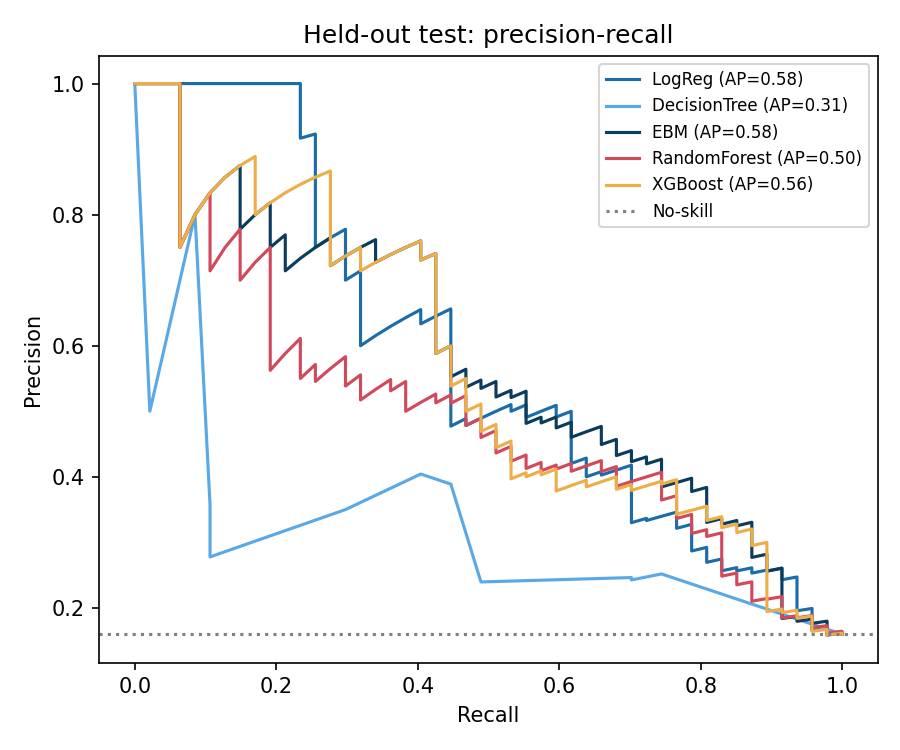

In [23]:
display(Image(FIG / 'pr_curves.png'))

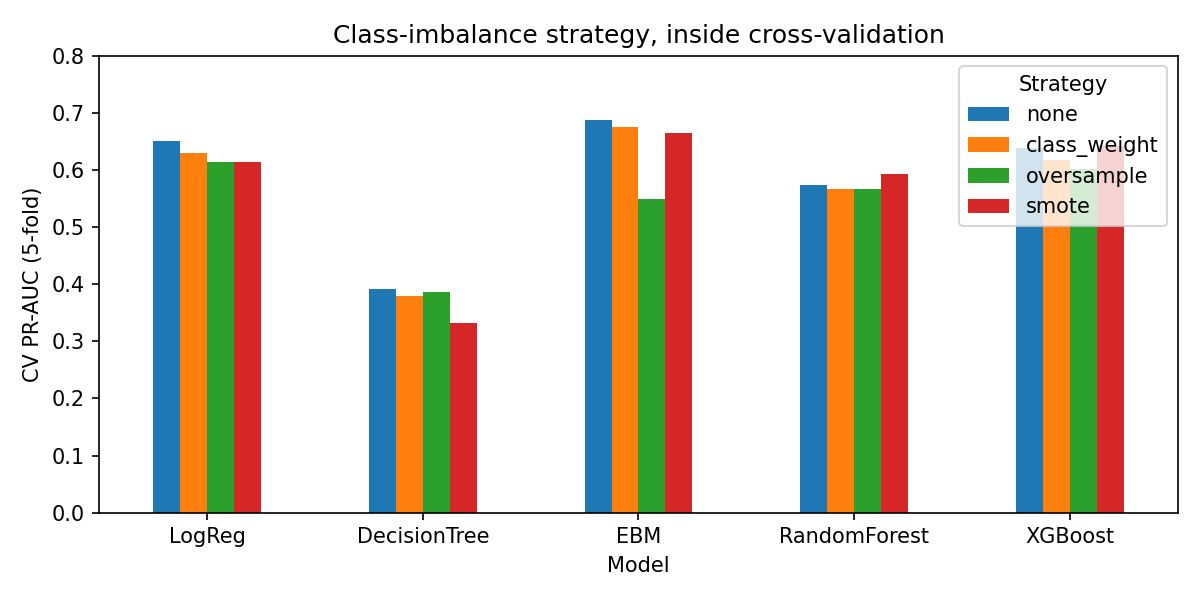

In [24]:
display(Image(FIG / 'imbalance_strategies.png'))

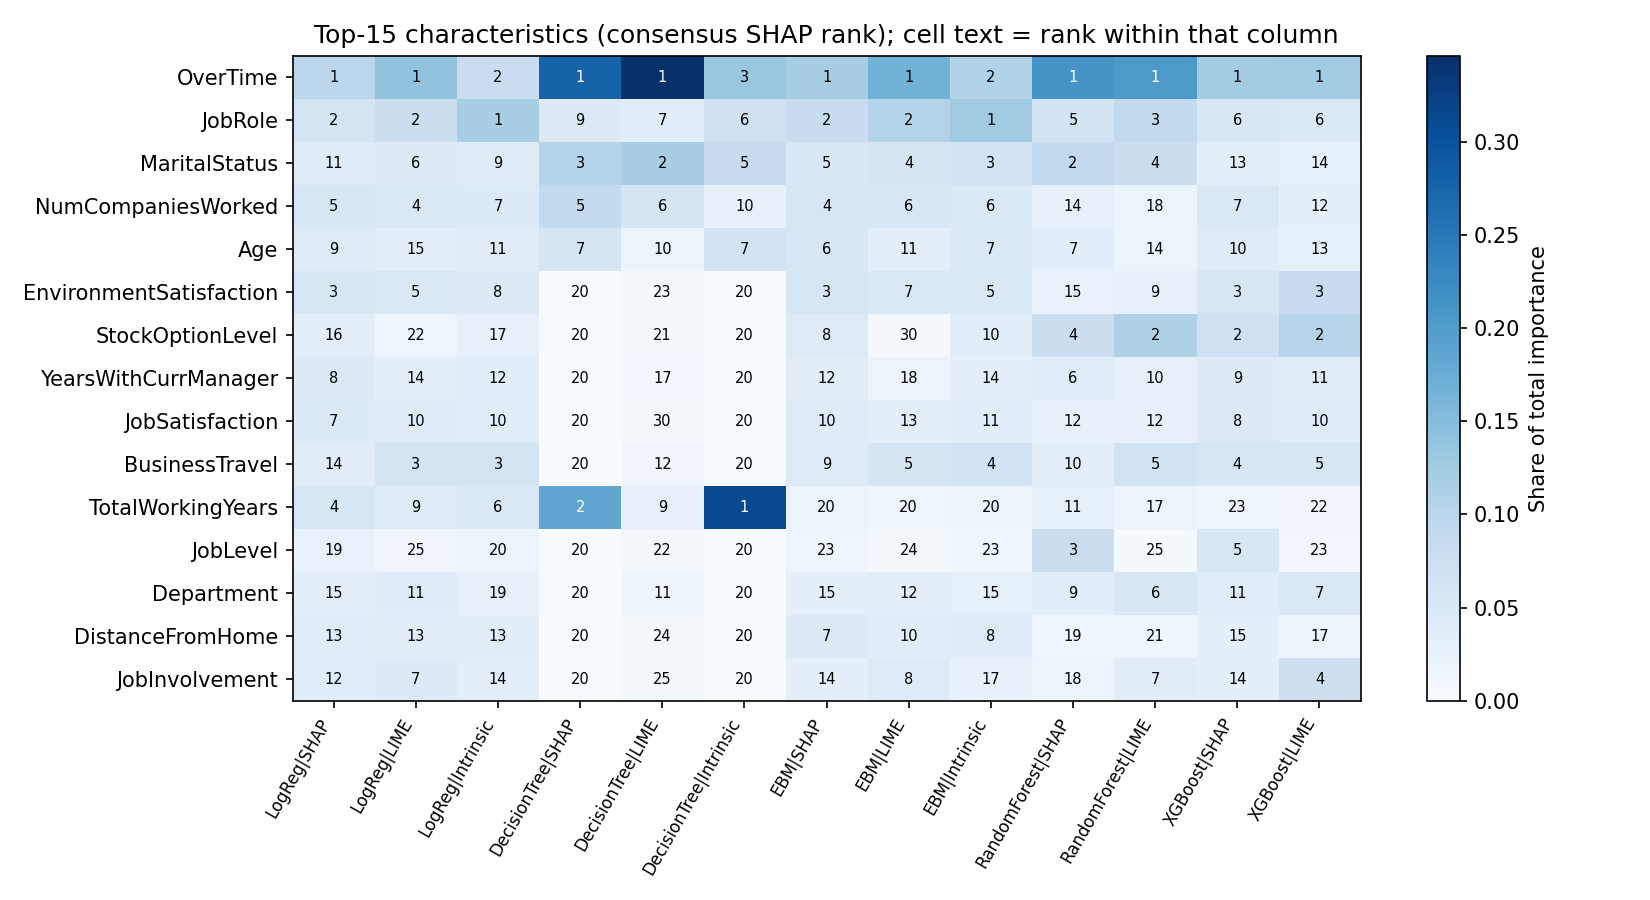

In [25]:
display(Image(FIG / 'global_importance_heatmap.png'))

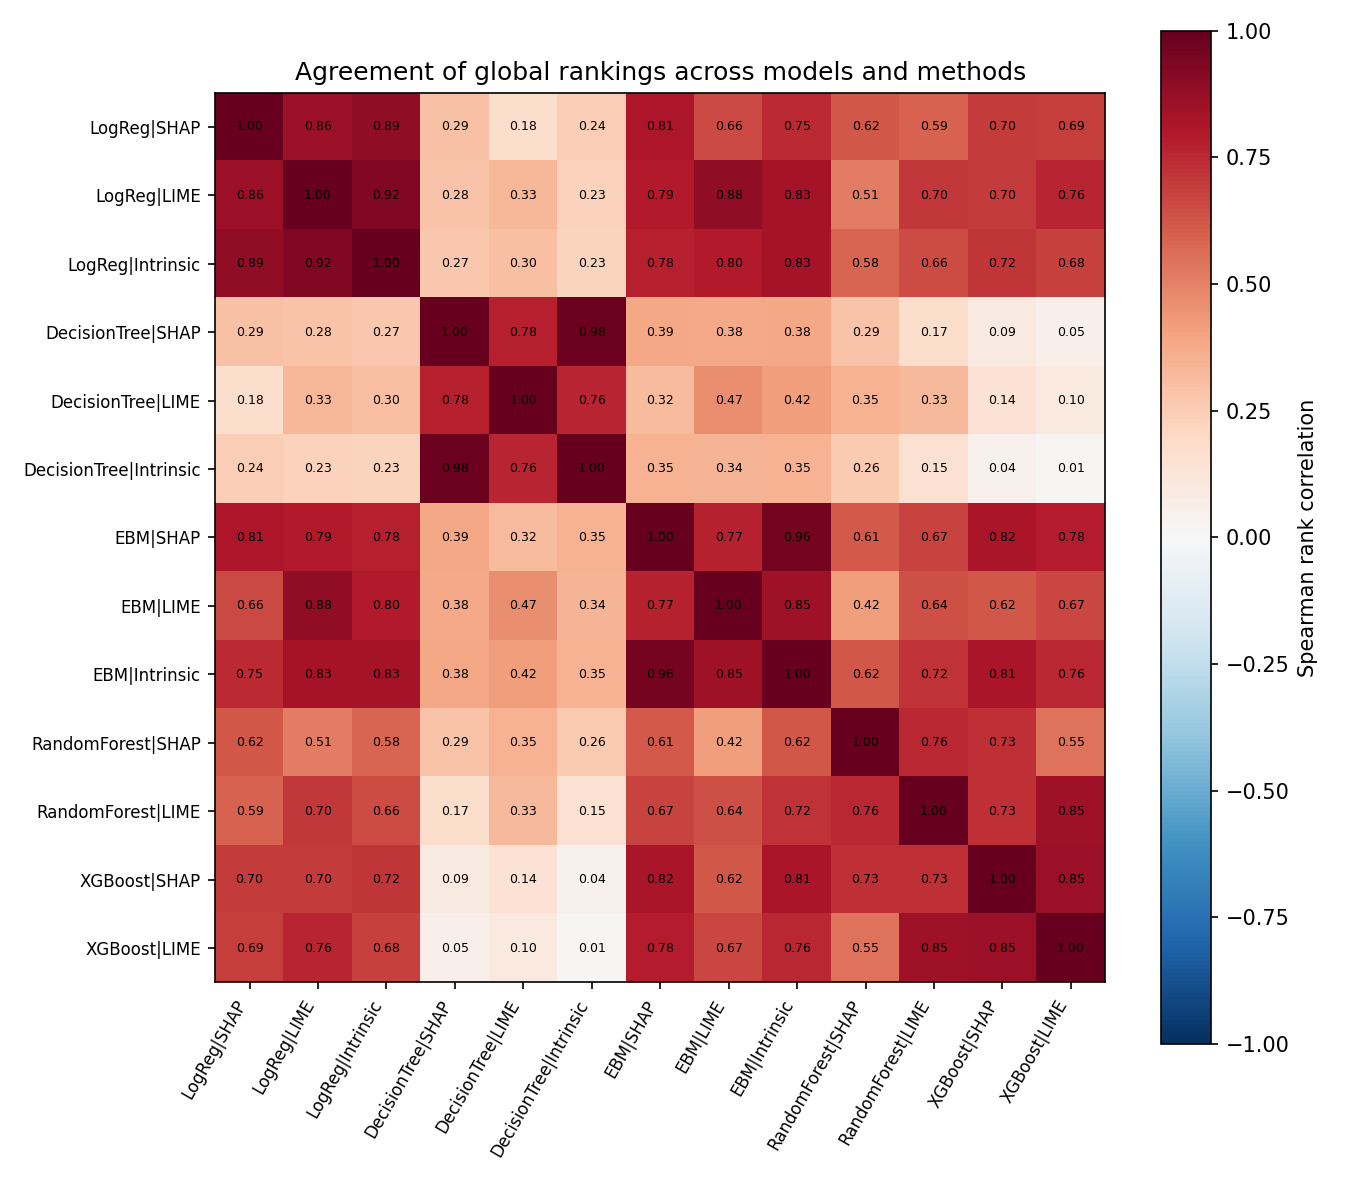

In [26]:
display(Image(FIG / 'rank_agreement.png'))

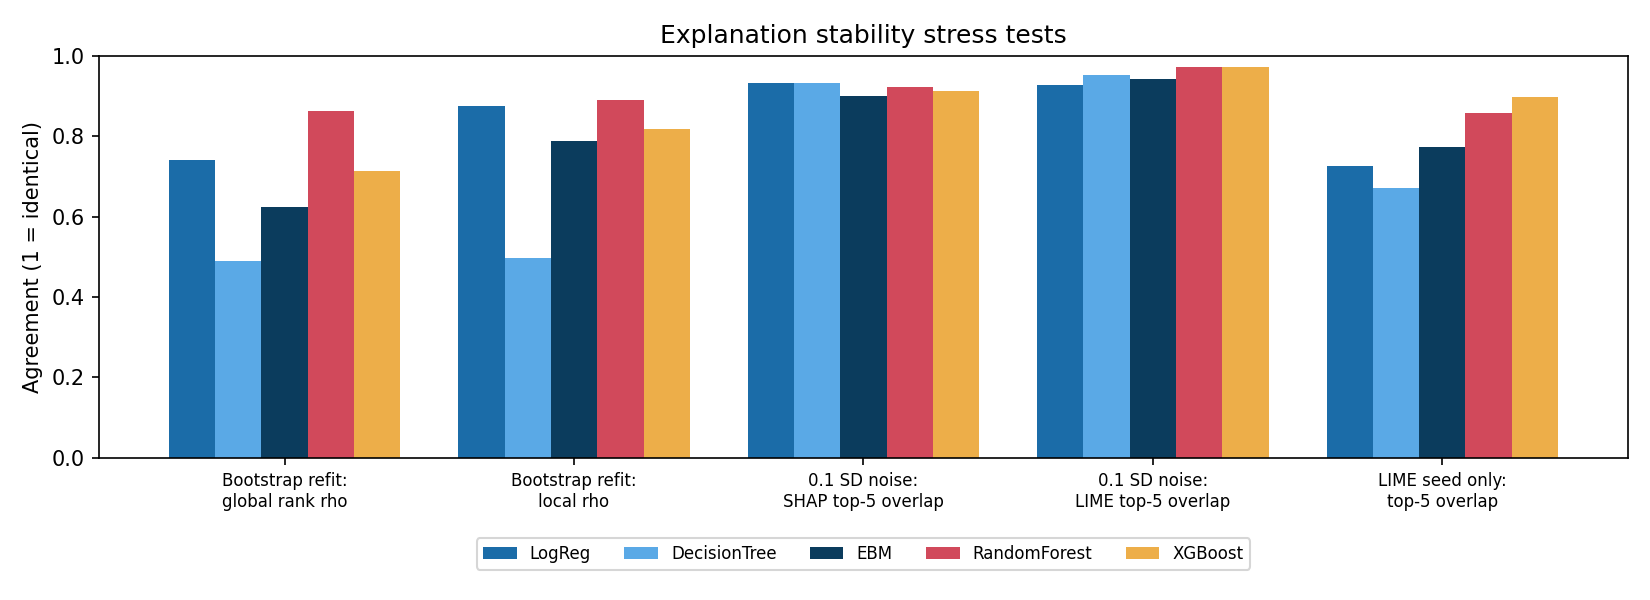

In [27]:
display(Image(FIG / 'stability.png'))

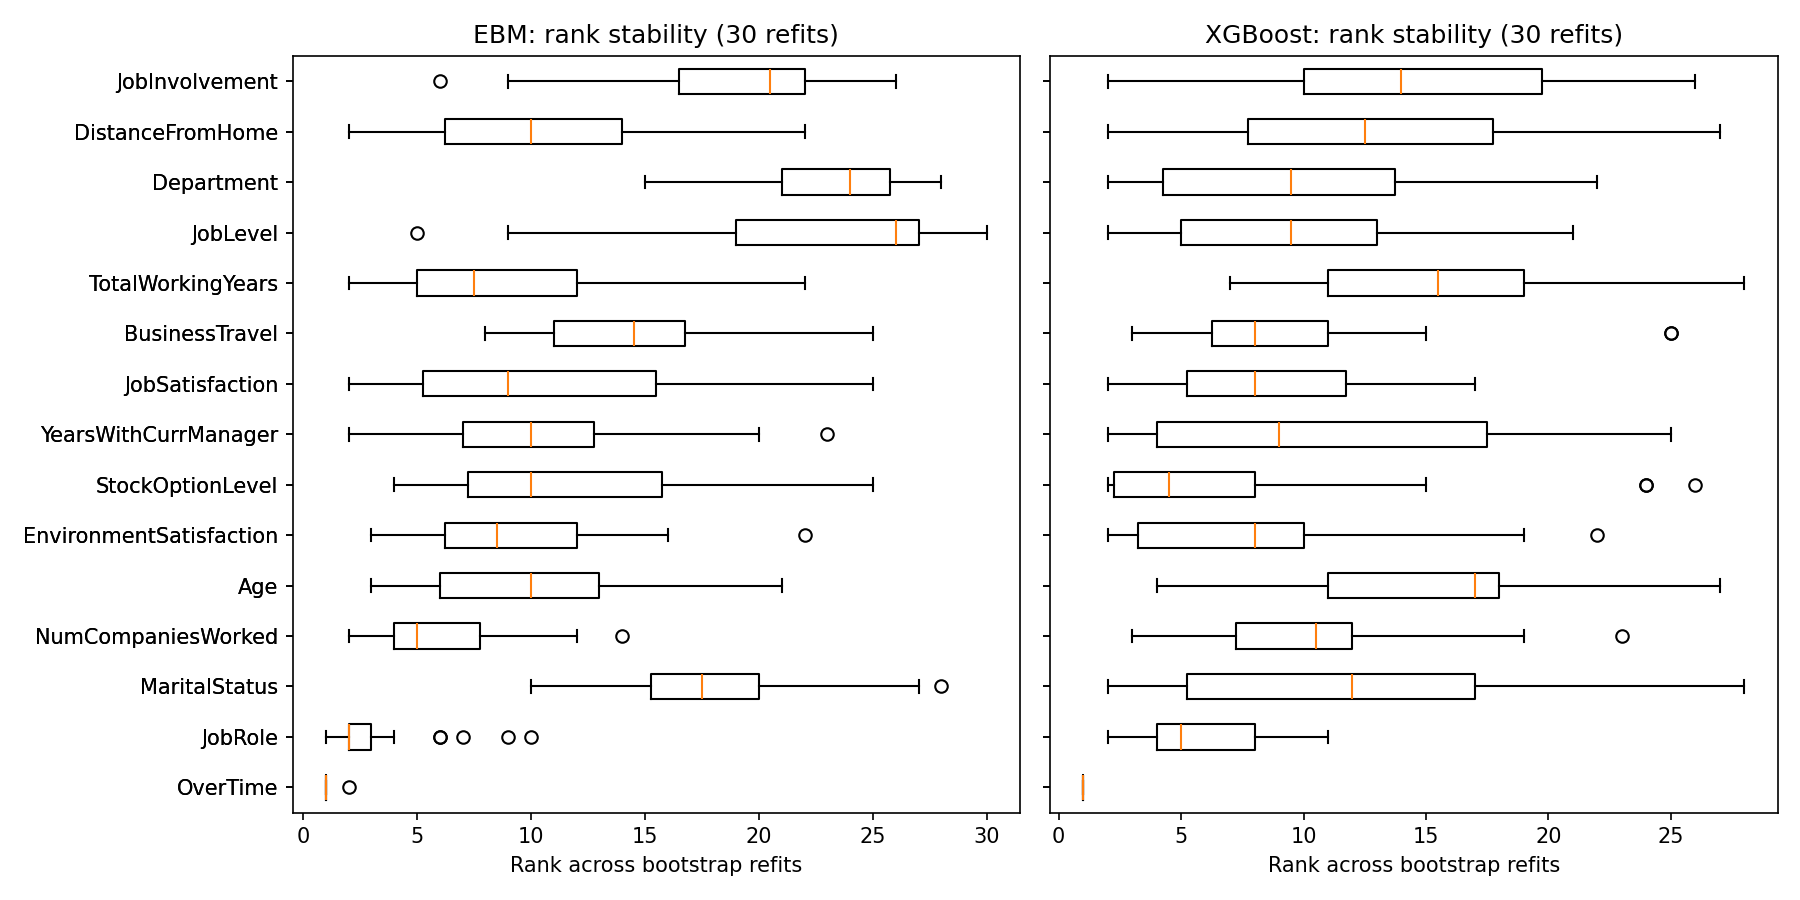

In [28]:
display(Image(FIG / 'bootstrap_rank_stability.png'))

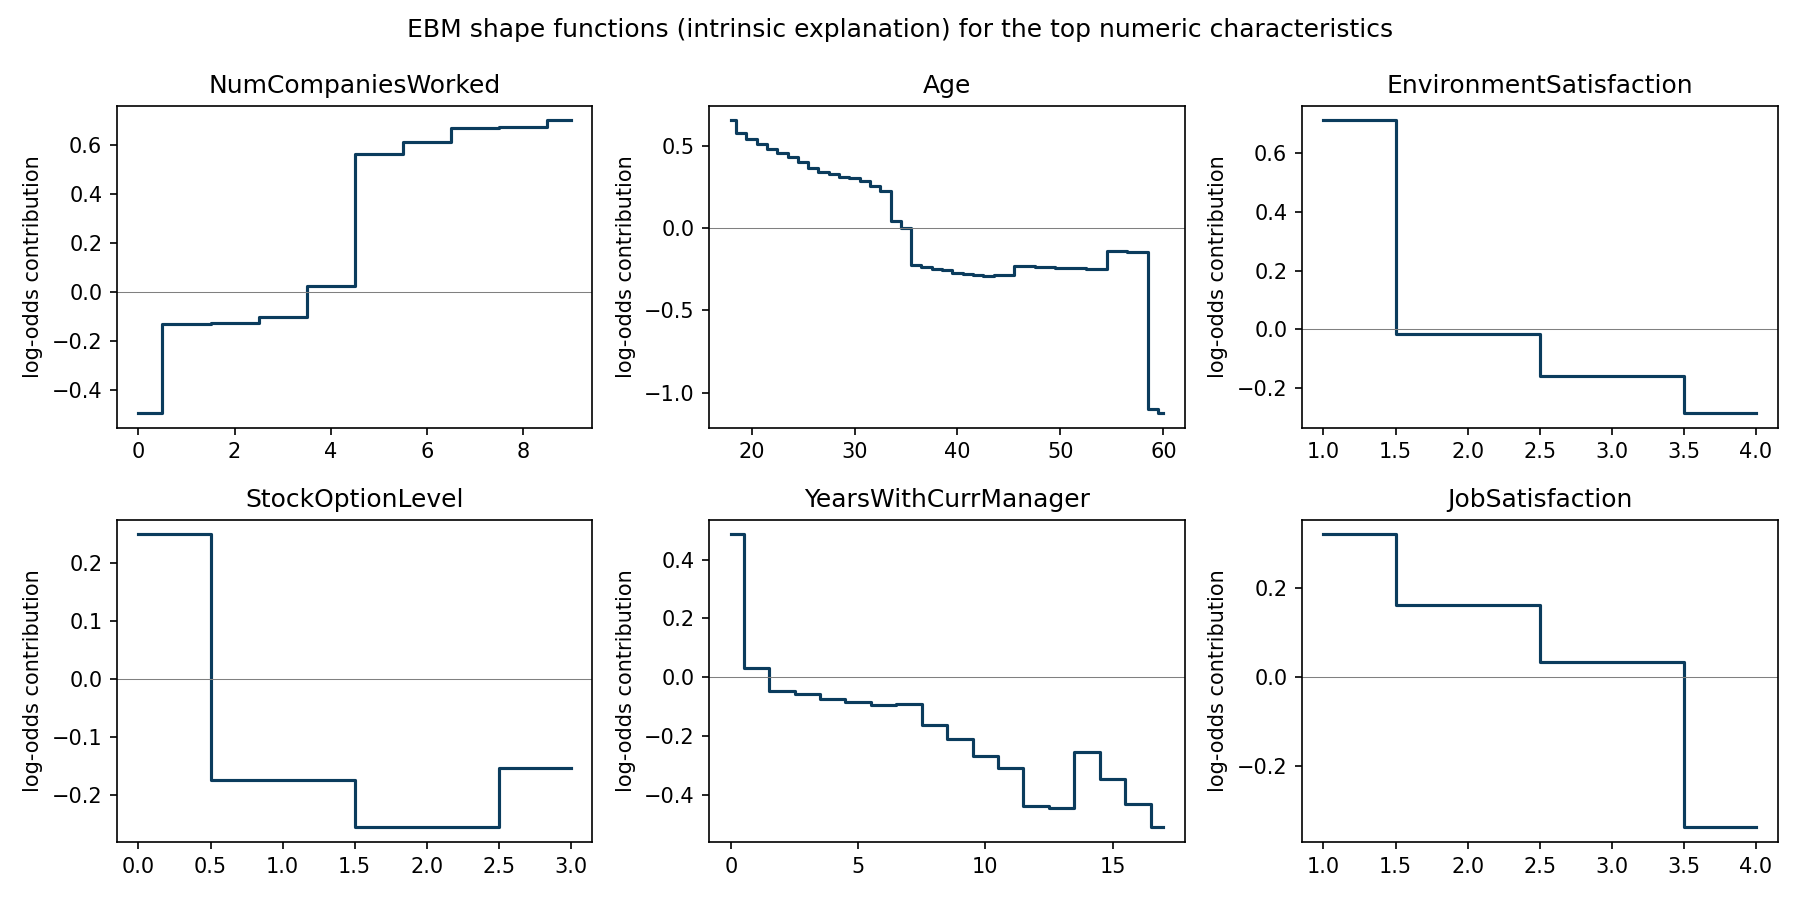

In [29]:
display(Image(FIG / 'ebm_shape_functions.png'))

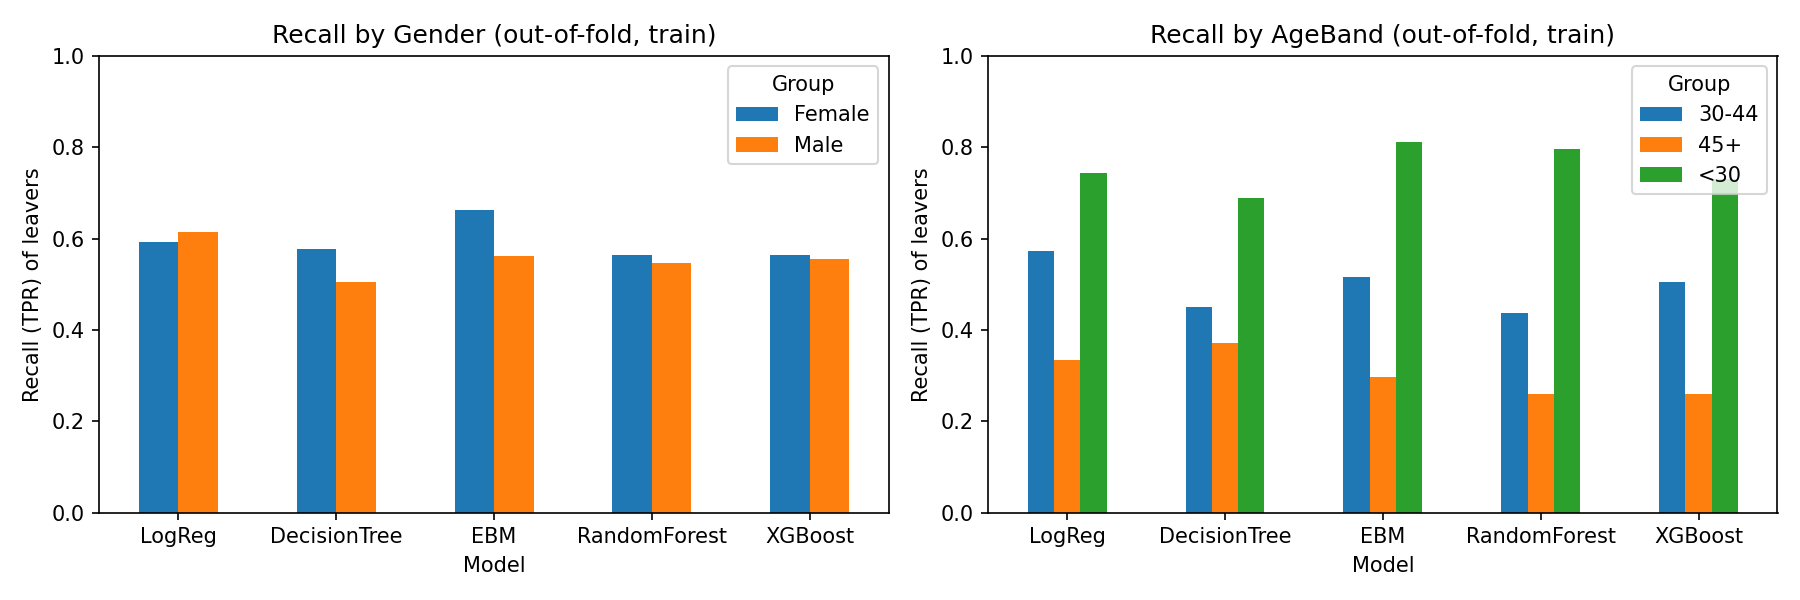

In [30]:
display(Image(FIG / 'subgroup_recall.png'))

## Summary

In [31]:
print(json.dumps(summary, indent=2, default=float))

{
  "n_rows": 1470,
  "n_features_encoded": 51,
  "n_characteristics": 30,
  "attrition_rate": 0.16122448979591836,
  "majority_accuracy": 0.8387755102040817,
  "n_train": 1176,
  "n_test": 294,
  "test_positives": 47,
  "lime_panel_size": 50,
  "best_black_box": "XGBoost",
  "recommended_glass_box": "EBM",
  "best_configs": [
    {
      "Model": "LogReg",
      "Strategy": "none",
      "Params": "{\"C\": 1.0}",
      "CV_PR_AUC": 0.6514396060738317
    },
    {
      "Model": "DecisionTree",
      "Strategy": "none",
      "Params": "{\"max_depth\": 4, \"min_samples_leaf\": 10}",
      "CV_PR_AUC": 0.3912348616100141
    },
    {
      "Model": "EBM",
      "Strategy": "none",
      "Params": "{\"max_leaves\": 2}",
      "CV_PR_AUC": 0.6870620097524097
    },
    {
      "Model": "RandomForest",
      "Strategy": "smote",
      "Params": "{\"max_depth\": 8, \"min_samples_leaf\": 5}",
      "CV_PR_AUC": 0.594067099740444
    },
    {
      "Model": "XGBoost",
      "Strategy": "smote